<a href="https://colab.research.google.com/github/vishwa24816/GARCH-Volatility-Model/blob/main/GARCH%20Volatility%20Model.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip install -q yfinance arch statsmodels matplotlib
import numpy as np, pandas as pd, yfinance as yf
import matplotlib.pyplot as plt
from arch import arch_model
from statsmodels.stats.diagnostic import acorr_ljungbox
plt.rcParams["figure.figsize"] = (12, 5)

2007-09-17 00:00:00 2026-11-02 00:00:00 4692


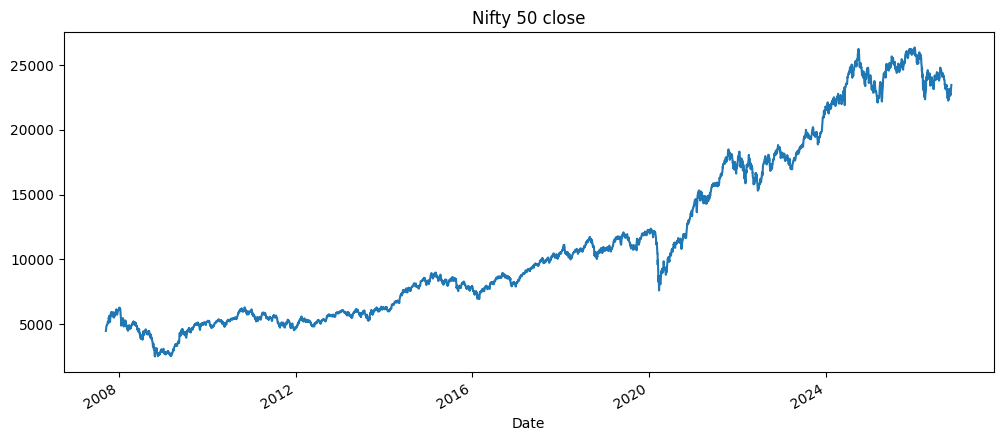

In [2]:
end = pd.Timestamp.today().normalize()
start = pd.Timestamp("2006-01-01")
df = yf.download("^NSEI", start=start, end=end, interval="1d", auto_adjust=True, progress=False)
df.columns = df.columns.get_level_values(0)
px = df["Close"].dropna()
print(px.index.min(), px.index.max(), len(px))
px.plot(title="Nifty 50 close");

count    4691.000000
mean        0.035208
std         1.291634
min       -13.903756
25%        -0.523911
50%         0.055205
75%         0.648515
max        16.334315
Name: Close, dtype: float64


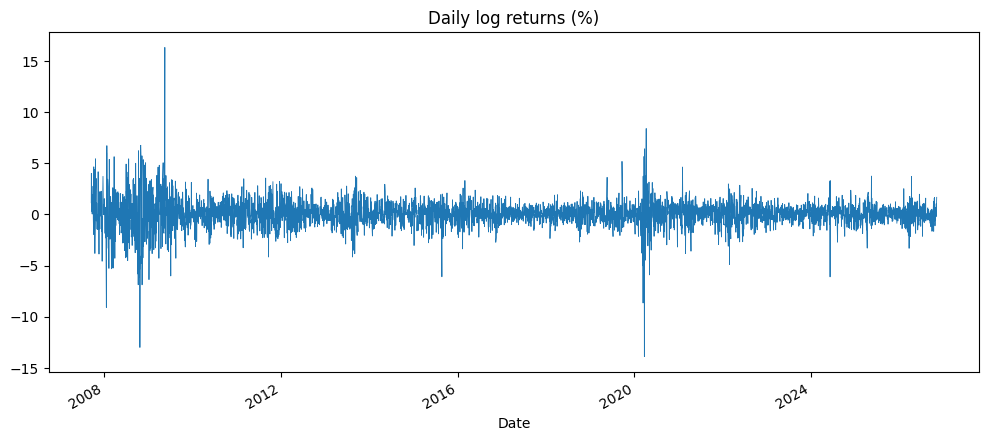

In [3]:
r = 100 * np.log(px).diff().dropna()
print(r.describe())
r.plot(title="Daily log returns (%)", lw=0.6);

In [4]:
specs = {
    "GARCH":     dict(vol="GARCH",  p=1, q=1),
    "GJR-GARCH": dict(vol="GARCH",  p=1, o=1, q=1),
    "EGARCH":    dict(vol="EGARCH", p=1, o=1, q=1),
}
fits = {n: arch_model(r, mean="Constant", dist="t", **kw).fit(disp="off")
        for n, kw in specs.items()}
print(fits["GJR-GARCH"].summary())

                      Constant Mean - GJR-GARCH Model Results                       
Dep. Variable:                        Close   R-squared:                       0.000
Mean Model:                   Constant Mean   Adj. R-squared:                  0.000
Vol Model:                        GJR-GARCH   Log-Likelihood:               -6614.81
Distribution:      Standardized Student's t   AIC:                           13241.6
Method:                  Maximum Likelihood   BIC:                           13280.3
                                              No. Observations:                 4691
Date:                      Tue, Nov 03 2026   Df Residuals:                     4690
Time:                              16:22:24   Df Model:                            1
                                 Mean Model                                 
                 coef    std err          t      P>|t|      95.0% Conf. Int.
----------------------------------------------------------------------------
mu  

In [5]:
rows = []
for n, f in fits.items():
    g = f.params.get("gamma[1]", np.nan)
    gp = f.pvalues.get("gamma[1]", np.nan)
    rows.append([n, f.loglikelihood, f.aic, f.bic, g, gp])
cmp = pd.DataFrame(rows, columns=["model", "loglik", "AIC", "BIC", "gamma", "gamma_pval"]).set_index("model")
cmp.round(4)

,loglik,AIC,BIC,gamma,gamma_pval
model,,,,,
GARCH,-6667.6256,13345.2512,13377.5182,NaN,NaN
GJR-GARCH,-6614.8141,13241.6281,13280.3486,0.1309,0.0
EGARCH,-6610.1502,13232.3005,13271.0209,-0.0912,0.0


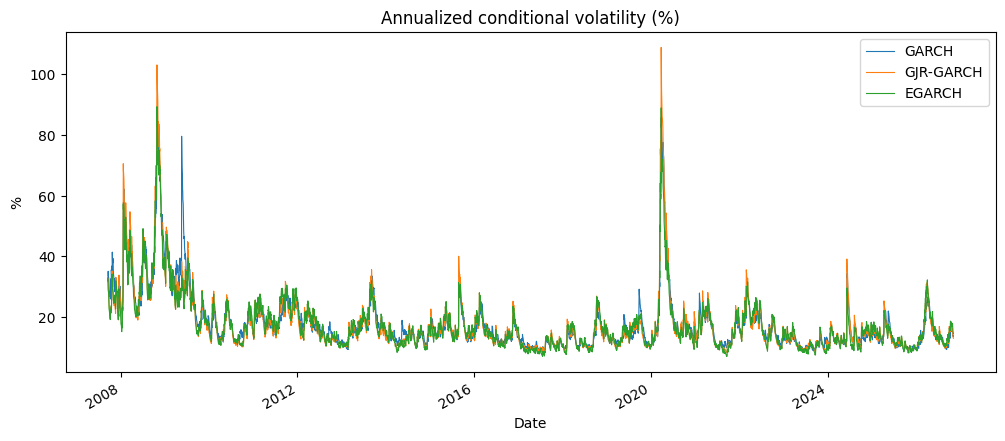

,GARCH,GJR-GARCH,EGARCH
Date,,,
2026-10-27,14.810715,14.866646,16.908866
2026-10-28,14.266644,14.323317,16.093255
2026-10-29,13.809269,13.902812,15.706723
2026-10-30,14.015605,13.528908,15.254996
2026-11-02,13.654704,13.088227,14.624388


In [6]:
vol = pd.DataFrame({n: f.conditional_volatility * np.sqrt(252) for n, f in fits.items()})
vol.plot(lw=0.8, title="Annualized conditional volatility (%)")
plt.ylabel("%"); plt.show()
vol.tail()

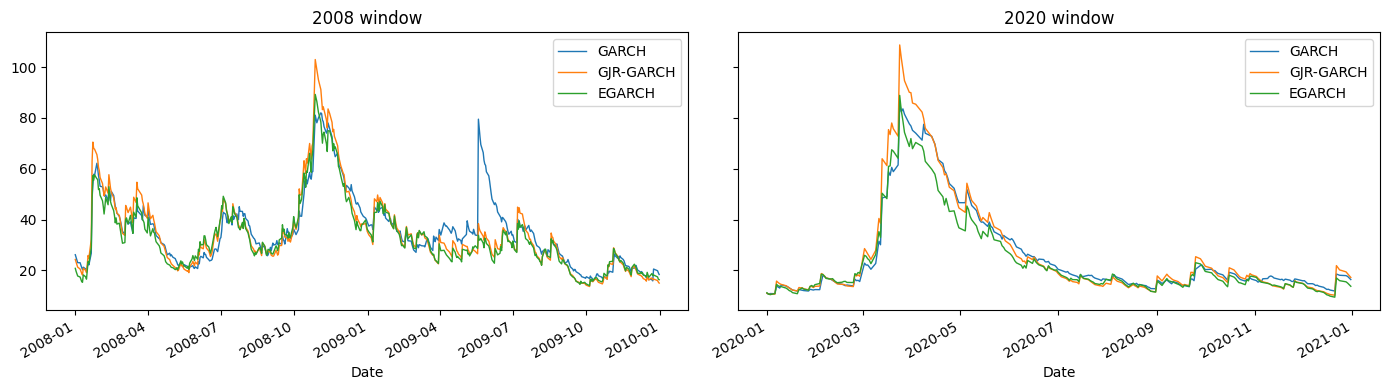

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4), sharey=True)
for a, (s, e) in zip(ax, [("2008-01-01", "2009-12-31"), ("2020-01-01", "2020-12-31")]):
    vol.loc[s:e].plot(ax=a, lw=1); a.set_title(f"{s[:4]} window")
plt.tight_layout(); plt.show()

In [8]:
for n, f in fits.items():
    z = f.std_resid.dropna()
    lb = acorr_ljungbox(z**2, lags=[10, 20], return_df=True)
    print(n, "| Ljung-Box p on z^2 (lag 10, 20):", lb["lb_pvalue"].round(3).tolist())

GARCH | Ljung-Box p on z^2 (lag 10, 20): [0.676, 0.89]
GJR-GARCH | Ljung-Box p on z^2 (lag 10, 20): [0.564, 0.781]
EGARCH | Ljung-Box p on z^2 (lag 10, 20): [0.124, 0.333]


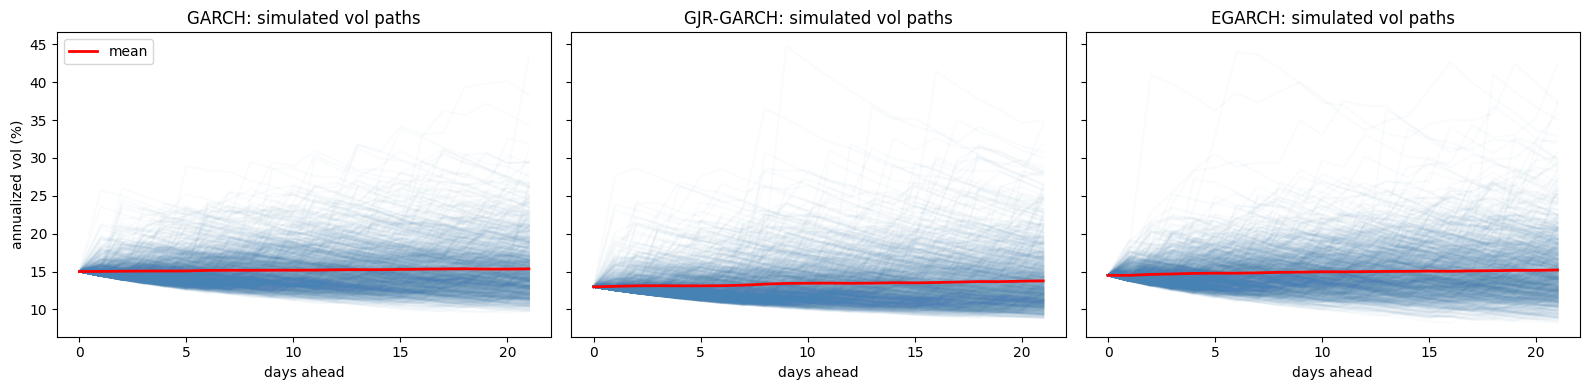

In [9]:
H, N = 22, 1000
sims = {}
for n, f in fits.items():
    fc = f.forecast(horizon=H, method="simulation", simulations=N, reindex=False)
    sims[n] = dict(
        vol=np.sqrt(fc.simulations.variances[-1]) * np.sqrt(252),   # (N, H) annualized %
        ret=fc.simulations.values[-1],                               # (N, H) daily returns %
    )

fig, axes = plt.subplots(1, 3, figsize=(16, 4), sharey=True)
for a, (n, s) in zip(axes, sims.items()):
    a.plot(s["vol"].T, color="steelblue", alpha=0.03)
    a.plot(s["vol"].mean(0), color="red", lw=2, label="mean")
    a.set_title(f"{n}: simulated vol paths"); a.set_xlabel("days ahead")
axes[0].set_ylabel("annualized vol (%)"); axes[0].legend()
plt.tight_layout(); plt.show()

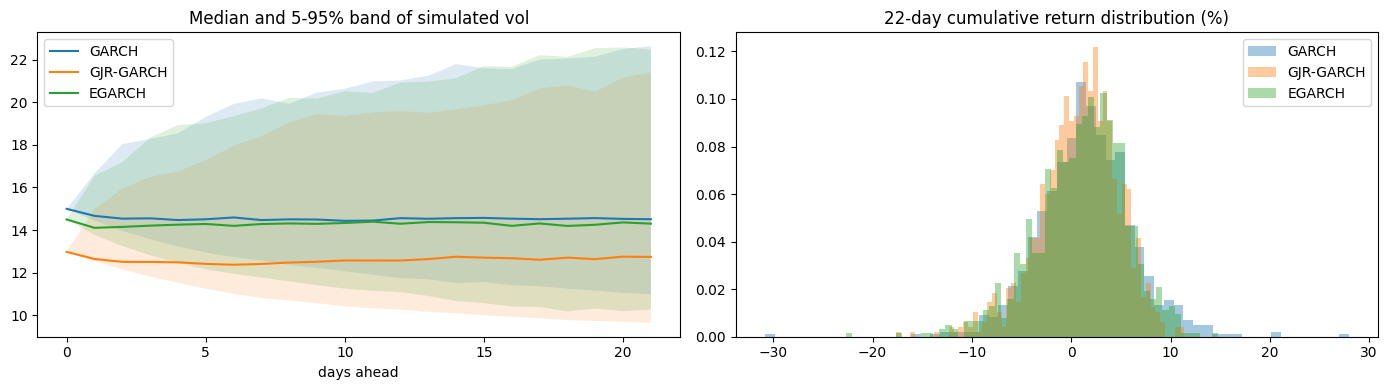

,avg vol (ann %),vol 95th pct,"5% VaR (22d, %)"
GARCH,15.19,20.73,-5.85
GJR-GARCH,13.38,19.10,-6.24
EGARCH,14.91,20.53,-7.24


In [10]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
for n, s in sims.items():
    q = np.percentile(s["vol"], [5, 50, 95], axis=0)
    ax[0].plot(q[1], label=n)
    ax[0].fill_between(range(H), q[0], q[2], alpha=0.15)
    cum = s["ret"].sum(1)
    ax[1].hist(cum, bins=60, alpha=0.4, label=n, density=True)
ax[0].set_title("Median and 5-95% band of simulated vol"); ax[0].set_xlabel("days ahead"); ax[0].legend()
ax[1].set_title(f"{H}-day cumulative return distribution (%)"); ax[1].legend()
plt.tight_layout(); plt.show()

summary = pd.DataFrame({n: {"avg vol (ann %)": s["vol"].mean(),
                            "vol 95th pct": np.percentile(s["vol"], 95),
                            "5% VaR (22d, %)": np.percentile(s["ret"].sum(1), 5)}
                        for n, s in sims.items()}).T
summary.round(2)